# Privacy-Aware Telemetry for Agentic Federated Continual Learning

This notebook is a **major experimental upgrade** designed to answer the specific weaknesses raised in review.

**What changed**
1. **Benchmark:** replaces `sklearn` Digits + synthetic rotation/blur domains with the real **Digits-Five** benchmark: MNIST → USPS → SVHN → MNIST-M → SynthDigits.
2. **Model:** replaces the 64→64→32→10 MLP with a compact 3-channel CNN using GroupNorm.
3. **Statistics:** paper mode uses **10 paired seeds** for the headline comparison and reports an exact paired sign-flip test, paired t-test, Wilcoxon test, 95% CI, and paired effect size.
4. **Action attribution:** learning rate is now **fixed across all controller actions**. The controller varies only epochs, replay ratio, and FedProx strength. A complete **2×2×2 policy-trace factorial ablation** isolates those three action components.
5. **Privacy:** evaluates telemetry budgets **ε ∈ {1,3,5,10}** at δ=1e-5 and plots the **counterfactual action-disagreement rate** versus the non-private decision at the same model state.
6. **Federated realism:** every round uses **partial participation** plus **client dropout**, with the exact same participation schedule across methods within each seed.
7. **Claim scope:** the title no longer says “privacy-preserving.” Differential privacy applies **only to the clipped 2-D controller telemetry**. The released model has **no DP guarantee**.
8. **Aggregation wording:** cryptographic secure aggregation is **not claimed as implemented**. A separate arithmetic masking sanity check is included only to verify mask cancellation logic.

> **Important privacy interpretation.** The experiment simulates the *noisy aggregate telemetry* that would be exposed to the controller after an aggregation/privacy gateway. It does not implement a production cryptographic secure-aggregation protocol. Therefore the paper should claim a telemetry-DP control mechanism, not end-to-end private federated learning.

### Reproducibility modes
- `RUN_MODE="paper"`: 10 seeds for the main comparison, 5 seeds for factorial ablation, 5 seeds for the ε sweep.
- `RUN_MODE="smoke"`: one seed only. Use this to debug.

The Digits-Five archive is the preprocessed benchmark used by the public FedBN codebase. The notebook verifies the archive SHA-256 before loading it.

In [1]:
# Cell 01 | Cell 01 | Install Colab dependencies only if missing.
# Cell 01 | Install Colab dependencies only if missing.
import importlib.util, subprocess, sys
for package, module in [('huggingface_hub', 'huggingface_hub'), ('requests', 'requests'),
                        ('scipy', 'scipy'), ('pandas', 'pandas'), ('matplotlib', 'matplotlib')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])


In [2]:
# Cell 02 | import os, math, random, time, json, hashlib, zipfile, itertools, warnings
import os, math, random, time, json, hashlib, zipfile, itertools, warnings
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=UserWarning)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(min(4, os.cpu_count() or 1))

print("Device:", DEVICE)
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

RUN_MODE = "paper"   # "paper" or "smoke"

if RUN_MODE == "paper":
    MAIN_SEEDS = list(range(10))       # headline statistics: 10 paired seeds
    ABLATION_SEEDS = list(range(5))    # factorial ablation
    EPS_SWEEP_SEEDS = list(range(5))   # privacy sweep
else:
    MAIN_SEEDS = [0]
    ABLATION_SEEDS = [0]
    EPS_SWEEP_SEEDS = [0]

CFG = {
    "n_clients": 10,
    "rounds_per_domain": 4,
    "client_fraction": 0.70,
    "dropout_rate": 0.10,
    "samples_per_client_round": 256,
    "batch_size": 64,
    "buffer_capacity": 200,
    "telemetry_sample_cap": 64,
    "telemetry_clip": 1.0,
    "delta": 1e-5,
    "epsilon_main": 10.0,
    "dirichlet_alpha": 0.30,
    "min_client_samples": 60,
    "test_cap_per_domain": 2000,
    "lr": 0.03,  # FIXED across all adaptive actions to remove the fourth bundled variable
}

DOMAIN_ORDER = ["MNIST", "USPS", "SVHN", "MNIST_M", "SynthDigits"]

ACTION_TARGETS = {
    "plastic":   {"replay_ratio": 0.15, "prox_mu": 0.00, "epochs": 2},
    "balanced":  {"replay_ratio": 0.35, "prox_mu": 0.01, "epochs": 1},
    "retention": {"replay_ratio": 0.55, "prox_mu": 0.03, "epochs": 2},
}
FIXED_BALANCED = ACTION_TARGETS["balanced"].copy()

# Optional: change to a mounted Drive folder to retain outputs after Colab resets.
OUTPUT_DIR = Path("/content/drive/MyDrive/pa_agentfcl_outputs") if os.environ.get("PA_AGENTFCL_USE_DRIVE") == "1" else Path("/content/pa_agentfcl_outputs" if Path("/content").exists() else "pa_agentfcl_outputs")
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)

print("Run mode:", RUN_MODE)
print("Main seeds:", MAIN_SEEDS)
print("Action space:", ACTION_TARGETS)
# Reviewer extensions: executed by Run all in paper mode unless disabled here.
RUN_REVIEWER_DIAGNOSTICS = True
RUN_BUDGET_CONTROLS = (RUN_MODE == "paper")
RUN_DOMAIN_ORDER_SENSITIVITY = False  # optional heavy extension: ~several full runs
RUN_CLIENT_SCALE = False               # optional heavy extension: 50/100 clients
RUN_THRESHOLD_SENSITIVITY = False      # optional full-training threshold perturbations
RUN_LONGER_EXPOSURE = False            # optional heavy extension
DRIFT_MODE = "same_model"             # recommended fix; set "legacy" ONLY to reproduce prior figures
DP_SCOPE = "conditional_fixed_model_path_only"  # NOT a full adaptive transcript DP guarantee
print('DP scope:', DP_SCOPE, '| drift mode:', DRIFT_MODE)


Device: cuda
PyTorch: 2.14.1+cu130
NumPy: 2.4.6
Pandas: 2.2.3
Run mode: paper
Main seeds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Action space: {'plastic': {'replay_ratio': 0.15, 'prox_mu': 0.0, 'epochs': 2}, 'balanced': {'replay_ratio': 0.35, 'prox_mu': 0.01, 'epochs': 1}, 'retention': {'replay_ratio': 0.55, 'prox_mu': 0.03, 'epochs': 2}}
DP scope: conditional_fixed_model_path_only | drift mode: same_model


In [3]:
# Cell 03 | ---------- Digits-Five download and preprocessing ----------
# ---------- Digits-Five download and preprocessing ----------
# Public FedBN benchmark mirror:
DIGIT5_URL = "https://huggingface.co/datasets/Jemary/FedBN_Dataset/resolve/main/digit_dataset.zip?download=true"
DIGIT5_SHA256 = "6c006e41ce16404aab520895a5c510166453c8b58ed2e7eb7e23e133e1fa4221"

DATA_ROOT = Path("/content/pa_agentfcl_digit5") if Path("/content").exists() else Path("./pa_agentfcl_digit5")
ARCHIVE_PATH = DATA_ROOT / "digit_dataset.zip"
EXTRACT_ROOT = DATA_ROOT / "extracted"

def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)
    return h.hexdigest()

def download_file(url, dest):
    import requests
    dest.parent.mkdir(parents=True, exist_ok=True)
    tmp = dest.with_suffix(dest.suffix + ".part")
    with requests.get(url, stream=True, timeout=60) as r:
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0))
        done = 0
        with open(tmp, "wb") as f:
            for chunk in r.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)
                    done += len(chunk)
                    if total:
                        print(f"\rDownloading: {100*done/total:5.1f}%", end="")
    print()
    tmp.replace(dest)

def ensure_digit5():
    DATA_ROOT.mkdir(parents=True, exist_ok=True)
    if not ARCHIVE_PATH.exists():
        print("Downloading Digits-Five archive (~278 MB)...")
        try:
            from huggingface_hub import hf_hub_download
            downloaded = hf_hub_download(
                repo_id="Jemary/FedBN_Dataset",
                filename="digit_dataset.zip",
                repo_type="dataset",
                local_dir=str(DATA_ROOT),
            )
            downloaded = Path(downloaded)
            if downloaded.resolve() != ARCHIVE_PATH.resolve():
                downloaded.replace(ARCHIVE_PATH)
        except Exception as e:
            print("huggingface_hub download failed; falling back to HTTPS:", repr(e))
            download_file(DIGIT5_URL, ARCHIVE_PATH)

    digest = sha256_file(ARCHIVE_PATH)
    if digest != DIGIT5_SHA256:
        raise RuntimeError(
            "Digits-Five archive SHA-256 mismatch. "
            f"Expected {DIGIT5_SHA256}, got {digest}. Delete the file and retry."
        )
    print("PASS: Digits-Five archive SHA-256 verified.")

    if not EXTRACT_ROOT.exists():
        EXTRACT_ROOT.mkdir(parents=True, exist_ok=True)
        print("Extracting archive...")
        with zipfile.ZipFile(ARCHIVE_PATH, "r") as zf:
            zf.extractall(EXTRACT_ROOT)

def find_domain_dir(domain_name):
    matches = [
        p for p in EXTRACT_ROOT.rglob(domain_name)
        if p.is_dir() and (p / "test.pkl").exists() and (p / "partitions").exists()
    ]
    if not matches:
        raise FileNotFoundError(f"Could not locate extracted domain directory for {domain_name}.")
    return matches[0]

def load_pickle_pair(path):
    # The archive hash is verified before any pickle is loaded.
    obj = np.load(path, allow_pickle=True)
    if not (isinstance(obj, tuple) and len(obj) == 2):
        try:
            obj = tuple(obj)
        except Exception as e:
            raise ValueError(f"Unexpected data format in {path}") from e
    X, y = obj
    return np.asarray(X), np.asarray(y, dtype=np.int64).reshape(-1)

def stratified_cap(X, y, cap, seed=12345):
    if cap is None or len(y) <= cap:
        return X, y
    rng = np.random.default_rng(seed)
    chosen = []
    classes = np.unique(y)
    base = cap // len(classes)
    remainder = cap - base * len(classes)
    for i, cls in enumerate(classes):
        idx = np.flatnonzero(y == cls)
        take = min(len(idx), base + (1 if i < remainder else 0))
        chosen.extend(rng.choice(idx, size=take, replace=False).tolist())
    chosen = np.array(chosen, dtype=np.int64)
    rng.shuffle(chosen)
    return X[chosen], y[chosen]

def canonicalize_uint8(images):
    # Convert arrays to canonical N x 32 x 32 x 3 uint8 so replay works across domains.
    a = np.asarray(images)
    if a.ndim == 3:  # N,H,W
        t = torch.from_numpy(a).unsqueeze(1).float()
    elif a.ndim == 4 and a.shape[-1] in (1, 3):
        t = torch.from_numpy(a).permute(0, 3, 1, 2).float()
    elif a.ndim == 4 and a.shape[1] in (1, 3):
        t = torch.from_numpy(a).float()
    else:
        raise ValueError(f"Unsupported image array shape: {a.shape}")

    if float(t.max()) <= 1.5:
        t = t * 255.0

    if t.shape[1] == 1:
        t = t.repeat(1, 3, 1, 1)

    if tuple(t.shape[-2:]) != (32, 32):
        t = F.interpolate(t, size=(32, 32), mode="bilinear", align_corners=False)

    t = t.round().clamp(0, 255).to(torch.uint8)
    return t.permute(0, 2, 3, 1).contiguous().cpu().numpy()

def load_digit5_domains():
    ensure_digit5()
    domains = []
    for d_idx, name in enumerate(DOMAIN_ORDER):
        ddir = find_domain_dir(name)

        part_files = sorted(
            (ddir / "partitions").glob("train_part*.pkl"),
            key=lambda p: int(p.stem.replace("train_part", ""))
        )
        if not part_files:
            raise FileNotFoundError(f"No train partitions found for {name}")

        xs, ys = [], []
        for p in part_files:
            Xp, yp = load_pickle_pair(p)
            xs.append(Xp)
            ys.append(yp)
        Xtr_raw = np.concatenate(xs, axis=0)
        ytr = np.concatenate(ys, axis=0)

        Xte_raw, yte = load_pickle_pair(ddir / "test.pkl")
        Xte_raw, yte = stratified_cap(
            Xte_raw, yte, CFG["test_cap_per_domain"], seed=5000 + d_idx
        )

        Xtr = canonicalize_uint8(Xtr_raw)
        Xte = canonicalize_uint8(Xte_raw)

        bad_labels = set(np.unique(ytr)) - set(range(10))
        if bad_labels:
            raise ValueError(f"Unexpected labels in {name}: {sorted(bad_labels)}")

        domains.append({
            "name": name,
            "train_x": Xtr,
            "train_y": ytr.astype(np.int64),
            "test_x": Xte,
            "test_y": yte.astype(np.int64),
        })
        print(
            f"{name:11s} train={len(ytr):5d} test={len(yte):5d} "
            f"shape={Xtr.shape[1:]}"
        )

    return domains

domains = load_digit5_domains()
print("Loaded domain stream:", " -> ".join(d["name"] for d in domains))

digit_dataset.zip: reconstructing file:   0%|          |  0.00B /  278MB            

digit_dataset.zip: downloading bytes:           |  0.00B            

PASS: Digits-Five archive SHA-256 verified.
Extracting archive...
MNIST       train= 7438 test= 2000 shape=(32, 32, 3)
USPS        train= 7438 test= 1860 shape=(32, 32, 3)
SVHN        train= 7438 test= 2000 shape=(32, 32, 3)
MNIST_M     train= 7438 test= 2000 shape=(32, 32, 3)
SynthDigits train= 7438 test= 2000 shape=(32, 32, 3)
Loaded domain stream: MNIST -> USPS -> SVHN -> MNIST_M -> SynthDigits


In [4]:
# Cell 04 | ---------- Model, data wrappers, replay, state utilities ----------
# ---------- Model, data wrappers, replay, state utilities ----------

def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

class UInt8ImageDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        x = torch.from_numpy(self.X[idx]).permute(2, 0, 1).float()
        x = x / 127.5 - 1.0
        return x, torch.tensor(int(self.y[idx]), dtype=torch.long)

class DigitCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.GroupNorm(4, 32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.GroupNorm(8, 64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 96, 3, padding=1),
            nn.GroupNorm(8, 96),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((2, 2)),
        )
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(96 * 2 * 2, 128),
            nn.ReLU(inplace=True),
            nn.Linear(128, 10),
        )

    def encode(self, x):
        z = self.encoder(x)
        return torch.flatten(z, 1)

    def forward(self, x):
        return self.head(self.encoder(x))

def model_parameter_count():
    m = DigitCNN()
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

print(f"Trainable CNN parameters: {model_parameter_count():,}")

class ReplayBuffer:
    def __init__(self, capacity, seed):
        self.capacity = int(capacity)
        self.rng_add = np.random.default_rng(seed)
        self.x = np.empty((self.capacity, 32, 32, 3), dtype=np.uint8)
        self.y = np.empty((self.capacity,), dtype=np.int64)
        self.size = 0
        self.seen = 0

    def add_batch(self, X, y):
        for xi, yi in zip(X, y):
            self.seen += 1
            if self.size < self.capacity:
                j = self.size
                self.size += 1
            else:
                j = int(self.rng_add.integers(0, self.seen))
                if j >= self.capacity:
                    continue
            self.x[j] = xi
            self.y[j] = int(yi)

    def sample(self, n, seed):
        n = min(int(n), self.size)
        if n <= 0:
            return None, None
        rng = np.random.default_rng(seed)
        ids = rng.permutation(self.size)[:n]
        return self.x[ids].copy(), self.y[ids].copy()

    def all(self):
        if self.size == 0:
            return None, None
        return self.x[:self.size], self.y[:self.size]

def get_state(model):
    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

def set_state(model, state):
    model.load_state_dict({k: v.clone() for k, v in state.items()})

def state_delta(new_state, old_state):
    return {k: new_state[k] - old_state[k] for k in old_state}

def state_add(old_state, delta):
    return {k: old_state[k] + delta[k] for k in old_state}

def state_weighted_mean(deltas, weights):
    total = float(sum(weights))
    if total <= 0:
        raise ValueError("Aggregation weights must sum to a positive value.")
    out = {}
    for k in deltas[0]:
        acc = torch.zeros_like(deltas[0][k])
        for d, w in zip(deltas, weights):
            acc += d[k] * (float(w) / total)
        out[k] = acc
    return out

@torch.no_grad()
def evaluate(model, X, y, batch_size=512):
    model.eval()
    loader = DataLoader(UInt8ImageDataset(X, y), batch_size=batch_size, shuffle=False)
    correct = total = 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        pred = model(xb).argmax(1)
        correct += int((pred == yb).sum().cpu())
        total += len(yb)
    return correct / max(total, 1)

@torch.no_grad()
def mean_representation(model, X, sample_cap, seed):
    if len(X) == 0:
        raise ValueError("Cannot compute representation mean from an empty client batch.")
    rng = np.random.default_rng(seed)
    if len(X) > sample_cap:
        idx = rng.choice(len(X), size=sample_cap, replace=False)
        X = X[idx]
    dummy_y = np.zeros(len(X), dtype=np.int64)
    loader = DataLoader(
        UInt8ImageDataset(X, dummy_y),
        batch_size=min(128, len(X)),
        shuffle=False,
    )
    model.eval()
    feats = []
    for xb, _ in loader:
        z = model.encode(xb.to(DEVICE))
        feats.append(z.detach().cpu())
    return torch.cat(feats, dim=0).mean(0).numpy()

@torch.no_grad()
def replay_error(model, buffer):
    X, y = buffer.all()
    if X is None:
        return 0.0
    return 1.0 - evaluate(model, X, y, batch_size=256)

Trainable CNN parameters: 125,738


In [5]:
# Cell 05 | ---------- Non-IID clients, participation/dropout, telemetry DP, controller
# ---------- Non-IID clients, participation/dropout, telemetry DP, controller ----------

def dirichlet_partition(labels, n_clients, alpha, seed, min_size=1, max_tries=500):
    labels = np.asarray(labels)
    rng = np.random.default_rng(seed)
    classes = np.unique(labels)

    for _ in range(max_tries):
        client_lists = [[] for _ in range(n_clients)]
        for cls in classes:
            idx = np.flatnonzero(labels == cls)
            rng.shuffle(idx)
            p = rng.dirichlet(np.full(n_clients, alpha))
            cuts = (np.cumsum(p)[:-1] * len(idx)).astype(int)
            splits = np.split(idx, cuts)
            for c, part in enumerate(splits):
                client_lists[c].extend(part.tolist())

        parts = []
        for lst in client_lists:
            arr = np.asarray(lst, dtype=np.int64)
            rng.shuffle(arr)
            parts.append(arr)

        if min(len(p) for p in parts) >= min_size:
            return parts

    raise RuntimeError(
        f"Could not create Dirichlet partition with minimum {min_size} samples/client."
    )

def client_round_indices(client_indices, round_id, n_samples, seed):
    if len(client_indices) <= n_samples:
        return client_indices
    rng = np.random.default_rng(seed * 1_000_003 + round_id * 9_973 + 17)
    return rng.choice(client_indices, size=n_samples, replace=False)

def make_participation_schedule(seed, total_rounds, n_clients, fraction, dropout_rate):
    rng = np.random.default_rng(900_001 + seed)
    n_selected = max(2, int(math.ceil(fraction * n_clients)))
    schedule = []
    for _ in range(total_rounds):
        selected = rng.choice(n_clients, size=n_selected, replace=False).tolist()
        active = [c for c in selected if rng.random() >= dropout_rate]
        if len(active) < 2:
            remaining = [c for c in selected if c not in active]
            rng.shuffle(remaining)
            active.extend(remaining[: 2 - len(active)])
        schedule.append({"selected": selected, "active": active})
    return schedule

def solve_rho_for_epsilon(eps, delta):
    L = math.log(1.0 / delta)
    x = -math.sqrt(L) + math.sqrt(L + eps)
    return x * x

def epsilon_from_rho(rho, delta):
    return rho + 2.0 * math.sqrt(rho * math.log(1.0 / delta))

def zcdp_noise_multiplier(total_rounds, eps, delta):
    rho_total = solve_rho_for_epsilon(eps, delta)
    rho_round = rho_total / total_rounds
    sigma = 1.0 / math.sqrt(2.0 * rho_round)
    return rho_total, rho_round, sigma

def clip_l2(v, C):
    v = np.asarray(v, dtype=np.float64)
    n = np.linalg.norm(v)
    if n > C:
        v = v * (C / n)
    return v

def telemetry_vector(model, Xcur, buffer, prev_mean, seed, prev_images=None):
    cur_mean = mean_representation(
        model, Xcur, sample_cap=CFG["telemetry_sample_cap"], seed=seed
    )
    if DRIFT_MODE == "same_model" and prev_images is not None:
        # Both representations are extracted using the SAME current broadcast model.
        comparison_mean = mean_representation(model, prev_images,
            sample_cap=CFG["telemetry_sample_cap"], seed=seed + 777)
    else:
        comparison_mean = prev_mean
    if comparison_mean is None:
        drift = 0.0
    else:
        # Scale-normalized representation drift in [0,1] by triangle inequality.
        denom = np.linalg.norm(cur_mean) + np.linalg.norm(comparison_mean) + 1e-12
        drift = float(np.linalg.norm(cur_mean - comparison_mean) / denom)

    forget = float(replay_error(model, buffer))
    v = np.array([np.clip(drift, 0, 1), np.clip(forget, 0, 1)], dtype=np.float64)
    return clip_l2(v, CFG["telemetry_clip"]), cur_mean

def choose_action(tel, low_cut=0.15, retention_gap=0.10, plastic_gap=0.05):
    # Pre-specified transparent policy; both telemetry coordinates are on [0,1].
    drift, forget = float(tel[0]), float(tel[1])
    if max(drift, forget) < low_cut:
        return "balanced"
    if forget >= drift + retention_gap:
        return "retention"
    if drift >= forget + plastic_gap:
        return "plastic"
    return "balanced"

def materialize_action(action_name, factor_mask=(True, True, True)):
    # factor_mask = (adapt_epochs, adapt_replay, adapt_prox). LR is fixed.
    adapt_epochs, adapt_replay, adapt_prox = factor_mask
    target = ACTION_TARGETS[action_name]
    return {
        "epochs": target["epochs"] if adapt_epochs else FIXED_BALANCED["epochs"],
        "replay_ratio": target["replay_ratio"] if adapt_replay else FIXED_BALANCED["replay_ratio"],
        "prox_mu": target["prox_mu"] if adapt_prox else FIXED_BALANCED["prox_mu"],
        "lr": CFG["lr"],
    }

def fixed_action(method):
    if method == "FedAvg":
        return {"epochs": 1, "replay_ratio": 0.0, "prox_mu": 0.0, "lr": CFG["lr"]}
    if method == "FedProx":
        return {"epochs": 1, "replay_ratio": 0.0, "prox_mu": 0.03, "lr": CFG["lr"]}
    if method == "FedReplay":
        return {"epochs": 1, "replay_ratio": 0.35, "prox_mu": 0.01, "lr": CFG["lr"]}
    if method == "FedReplay2E":
        return {"epochs": 2, "replay_ratio": 0.35, "prox_mu": 0.01, "lr": CFG["lr"]}
    raise ValueError(method)

def local_train(global_state, Xcur, ycur, buffer, action, seed):
    seed_all(seed)
    model = DigitCNN().to(DEVICE)
    set_state(model, global_state)
    model.train()

    n_replay = int(round(len(Xcur) * action["replay_ratio"]))
    Xr, yr = buffer.sample(n_replay, seed=seed + 424_242)
    if Xr is not None:
        Xa = np.concatenate([Xcur, Xr], axis=0)
        ya = np.concatenate([ycur, yr], axis=0)
    else:
        Xa, ya = Xcur, ycur

    g = torch.Generator()
    g.manual_seed(seed)
    loader = DataLoader(
        UInt8ImageDataset(Xa, ya),
        batch_size=CFG["batch_size"],
        shuffle=True,
        generator=g,
        drop_last=False,
    )

    opt = torch.optim.SGD(
        model.parameters(), lr=action["lr"], momentum=0.9, weight_decay=1e-4
    )
    ref = {k: v.to(DEVICE) for k, v in global_state.items()}

    for _ in range(int(action["epochs"])):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(xb), yb)

            if action["prox_mu"] > 0:
                prox = torch.zeros((), device=DEVICE)
                for name, p in model.named_parameters():
                    prox = prox + torch.sum((p - ref[name]) ** 2)
                loss = loss + 0.5 * action["prox_mu"] * prox

            loss.backward()
            opt.step()

    return state_delta(get_state(model), global_state)

In [6]:
# Cell 06 | ---------- One complete federated continual-learning run ----------
# ---------- One complete federated continual-learning run ----------

def run_one(
    method,
    seed,
    domains,
    epsilon=None,
    forced_actions=None,
    factor_mask=(True, True, True),
    verbose=False,
    epoch_policy=None,
    forced_epoch_trace=None,
    threshold_policy=None,
):
    seed_all(10_000 + seed)

    n_domains = len(domains)
    total_rounds = CFG["rounds_per_domain"] * n_domains

    client_parts = []
    for di, d in enumerate(domains):
        parts = dirichlet_partition(
            d["train_y"],
            CFG["n_clients"],
            CFG["dirichlet_alpha"],
            seed=50_000 + seed * 101 + di,
            min_size=CFG["min_client_samples"],
        )
        client_parts.append(parts)

    schedule = make_participation_schedule(
        seed,
        total_rounds,
        CFG["n_clients"],
        CFG["client_fraction"],
        CFG["dropout_rate"],
    )

    model = DigitCNN().to(DEVICE)
    global_state = get_state(model)

    buffers = [
        ReplayBuffer(CFG["buffer_capacity"], seed=70_000 + seed * 100 + c)
        for c in range(CFG["n_clients"])
    ]
    prev_means = [None] * CFG["n_clients"]
    prev_images = [None] * CFG["n_clients"]

    if method == "PA-AgentFCL":
        if epsilon is None:
            epsilon = CFG["epsilon_main"]
        rho_total, rho_round, sigma = zcdp_noise_multiplier(
            total_rounds, epsilon, CFG["delta"]
        )
    else:
        rho_total = rho_round = sigma = 0.0

    rho_spent = 0.0
    best = [0.0] * n_domains
    hist = []
    action_counts = {"plastic": 0, "balanced": 0, "retention": 0}
    disagreement_count = 0
    adaptive_round_count = 0
    epoch_sum = 0.0
    client_epoch_executions = 0.0
    total_sgd_steps = 0
    total_training_examples = 0
    selected_total = 0
    active_total = 0

    round_id = 0

    for di, d in enumerate(domains):
        parts = client_parts[di]

        for _ in range(CFG["rounds_per_domain"]):
            sched = schedule[round_id]
            selected = sched["selected"]
            active = sched["active"]
            selected_total += len(selected)
            active_total += len(active)

            set_state(model, global_state)

            round_batches = {}
            tels = []
            curmeans = {}

            for c in active:
                idx = client_round_indices(
                    parts[c],
                    round_id=round_id,
                    n_samples=CFG["samples_per_client_round"],
                    seed=80_000 + seed * 100 + di * 10 + c,
                )
                Xcur = d["train_x"][idx]
                ycur = d["train_y"][idx]
                round_batches[c] = (Xcur, ycur)

                v, cm = telemetry_vector(
                    model,
                    Xcur,
                    buffers[c],
                    prev_means[c],
                    seed=90_000 + seed * 10_000 + round_id * 100 + c,
                    prev_images=prev_images[c],
                )
                tels.append(v)
                curmeans[c] = cm

            tel_mean = np.mean(tels, axis=0)
            policy_kwargs = threshold_policy or {}
            reference_action = choose_action(tel_mean, **policy_kwargs)
            # Distances to the three scalar policy conditions; these are descriptive
            # geometric margins, not calibrated probabilities of action stability.
            d0, f0 = map(float, tel_mean)
            boundary_margin = min(abs(max(d0, f0) - 0.15),
                                  abs((f0 - d0) - 0.10),
                                  abs((d0 - f0) - 0.05))

            if forced_actions is not None:
                action_name = forced_actions[round_id]
                tel_used = tel_mean.copy()
                action = materialize_action(action_name, factor_mask=factor_mask)

            elif method == "PA-AgentFCL":
                # Replacement client-level sensitivity of the active-client mean.
                # Participation/dropout are data-independent. We conservatively do
                # not claim privacy amplification from subsampling.
                sensitivity = 2.0 * CFG["telemetry_clip"] / len(active)
                noise_std = sigma * sensitivity
                rng = np.random.default_rng(
                    100_000_007 + seed * 1_000_003 + round_id * 101
                )
                tel_used = tel_mean + rng.normal(0, noise_std, size=2)

                # DP-safe post-processing.
                tel_used = np.clip(tel_used, 0.0, 1.0)
                action_name = choose_action(tel_used, **policy_kwargs)
                action = materialize_action(action_name, factor_mask=factor_mask)
                rho_spent += rho_round

                disagreement_count += int(action_name != reference_action)
                adaptive_round_count += 1

            elif method == "AgentFCL":
                tel_used = tel_mean.copy()
                action_name = reference_action
                action = materialize_action(action_name, factor_mask=factor_mask)

            else:
                tel_used = tel_mean.copy()
                action_name = "fixed"
                action = fixed_action(method)

            if forced_epoch_trace is not None:
                action = dict(action)
                action["epochs"] = int(forced_epoch_trace[round_id])
            elif epoch_policy == "fixed_two":
                action = dict(action)
                action["epochs"] = 2
            if action_name in action_counts:
                action_counts[action_name] += 1

            epoch_sum += action["epochs"]
            client_epoch_executions += len(active) * action["epochs"]

            deltas = []
            weights = []
            for c in active:
                Xcur, ycur = round_batches[c]
                delta = local_train(
                    global_state,
                    Xcur,
                    ycur,
                    buffers[c],
                    action,
                    seed=110_000_000 + seed * 1_000_000 + round_id * 100 + c,
                )
                deltas.append(delta)
                weights.append(len(ycur))
                n_replay = min(int(round(len(ycur) * action["replay_ratio"])), buffers[c].size)
                training_examples = len(ycur) + n_replay
                total_training_examples += training_examples * int(action["epochs"])
                total_sgd_steps += math.ceil(training_examples / CFG["batch_size"]) * int(action["epochs"])

            agg = state_weighted_mean(deltas, weights)
            global_state = state_add(global_state, agg)
            set_state(model, global_state)

            # Only successful/active clients update local memory/state.
            for c in active:
                Xcur, ycur = round_batches[c]
                buffers[c].add_batch(Xcur, ycur)
                prev_means[c] = curmeans[c]
                if DRIFT_MODE == "same_model":
                    # Save the exact previous sampling pool for re-encoding next round.
                    prev_images[c] = Xcur.copy()

            seen_acc = []
            for ej in range(di + 1):
                a = evaluate(
                    model,
                    domains[ej]["test_x"],
                    domains[ej]["test_y"],
                )
                seen_acc.append(a)
                best[ej] = max(best[ej], a)

            hist.append({
                "method": method,
                "seed": seed,
                "round": round_id + 1,
                "domain_index": di,
                "domain": d["name"],
                "selected_clients": len(selected),
                "active_clients": len(active),
                "action": action_name,
                "reference_nonprivate_action": reference_action,
                "action_disagreement": (
                    int(action_name != reference_action)
                    if method == "PA-AgentFCL" else 0
                ),
                "boundary_margin_raw": float(boundary_margin),
                "telemetry_drift_rawmean": float(tel_mean[0]),
                "telemetry_forget_rawmean": float(tel_mean[1]),
                "telemetry_drift_used": float(tel_used[0]),
                "telemetry_forget_used": float(tel_used[1]),
                "avg_seen_accuracy": float(np.mean(seen_acc)),
                **{f"seen_accuracy_{domains[ej]['name']}": float(seen_acc[ej]) for ej in range(di+1)},
                "epochs": int(action["epochs"]),
                "replay_ratio": float(action["replay_ratio"]),
                "prox_mu": float(action["prox_mu"]),
                "sgd_steps_cumulative": int(total_sgd_steps),
                "training_examples_cumulative": int(total_training_examples),
            })

            round_id += 1

    final_acc = [
        evaluate(model, d["test_x"], d["test_y"])
        for d in domains
    ]

    forgetting = [
        max(0.0, best[j] - final_acc[j])
        for j in range(n_domains - 1)
    ]

    eps_spent = (
        epsilon_from_rho(rho_spent, CFG["delta"])
        if rho_spent > 0 else 0.0
    )

    selected_dropout = selected_total - active_total
    summary = {
        "method": method,
        "seed": seed,
        "epsilon_telemetry": float(eps_spent),
        "delta": CFG["delta"] if method == "PA-AgentFCL" else np.nan,
        "final_avg_accuracy": float(np.mean(final_acc)),
        "mean_forgetting": float(np.mean(forgetting)) if forgetting else 0.0,
        # Mean of max(0, maximum evaluation accuracy after domain first appears
        # through final round - accuracy at final round), over first D-1 domains.
        **{f"forgetting_{domains[j]['name']}": float(forgetting[j]) for j in range(n_domains-1)},
        "avg_local_epochs_per_round": float(epoch_sum / total_rounds),
        "client_epoch_executions": float(client_epoch_executions),
        "sgd_steps": int(total_sgd_steps),
        "training_example_exposures": int(total_training_examples),
        "drift_mode": DRIFT_MODE,
        "dp_guarantee_scope": DP_SCOPE,
        "avg_active_clients": float(active_total / total_rounds),
        "realized_participation_rate": float(
            active_total / (CFG["n_clients"] * total_rounds)
        ),
        "realized_dropout_given_selected": float(
            selected_dropout / max(selected_total, 1)
        ),
        "action_disagreement_rate": (
            float(disagreement_count / max(adaptive_round_count, 1))
            if method == "PA-AgentFCL" else np.nan
        ),
        **{
            f"final_{domains[j]['name']}": float(final_acc[j])
            for j in range(n_domains)
        },
        **{f"action_{k}": int(v) for k, v in action_counts.items()},
    }

    if verbose:
        print(
            f"{method:13s} seed={seed:2d} "
            f"acc={100*summary['final_avg_accuracy']:.2f} "
            f"forget={100*summary['mean_forgetting']:.2f} "
            f"epochs/rnd={summary['avg_local_epochs_per_round']:.2f}"
        )

    return summary, hist

def run_methods(methods, seeds, domains, epsilon_main=10.0):
    all_sum = []
    all_hist = []
    t0 = time.time()

    for seed in seeds:
        for method in methods:
            key = OUTPUT_DIR / f"checkpoint_{method}_seed{seed}_eps{epsilon_main:g}_drift{DRIFT_MODE}.json"
            histkey = key.with_suffix('.history.json')
            if key.exists() and histkey.exists():
                print('Loading completed checkpoint:', key.name)
                all_sum.append(json.loads(key.read_text()))
                all_hist.extend(json.loads(histkey.read_text()))
                continue
            print(f'Running {method}, seed {seed}; saving at completion', flush=True)
            eps = epsilon_main if method == "PA-AgentFCL" else None
            sm, hs = run_one(
                method,
                seed,
                domains,
                epsilon=eps,
                verbose=True,
            )
            all_sum.append(sm)
            all_hist.extend(hs)
            key.write_text(json.dumps(sm, indent=2, default=float))
            histkey.write_text(json.dumps(hs, indent=2, default=float))

    print(f"Elapsed: {(time.time() - t0) / 60:.1f} minutes")
    return pd.DataFrame(all_sum), pd.DataFrame(all_hist)

In [7]:
# Cell 07 | ---------- Main paired-seed comparison ----------
# ---------- Main paired-seed comparison ----------

MAIN_METHODS = [
    "FedAvg",
    "FedProx",
    "FedReplay",
    "FedReplay2E",
    "AgentFCL",
    "PA-AgentFCL",
]

main_results, main_history = run_methods(
    MAIN_METHODS,
    MAIN_SEEDS,
    domains,
    epsilon_main=CFG["epsilon_main"],
)

main_results.to_csv(OUTPUT_DIR / "main_per_seed_results.csv", index=False)
main_history.to_csv(OUTPUT_DIR / "main_round_history.csv", index=False)

summary_rows = []
for method, g in main_results.groupby("method", sort=False):
    row = {"method": method, "n_seeds": len(g)}
    for col in [
        "final_avg_accuracy",
        "mean_forgetting",
        "avg_local_epochs_per_round",
        "client_epoch_executions",
        "avg_active_clients",
    ]:
        row[f"{col}_mean"] = g[col].mean()
        row[f"{col}_std"] = g[col].std(ddof=1) if len(g) > 1 else 0.0
    row["epsilon_telemetry"] = g["epsilon_telemetry"].max()
    summary_rows.append(row)

main_summary = pd.DataFrame(summary_rows)
main_summary.to_csv(OUTPUT_DIR / "main_summary.csv", index=False)

display_cols = [
    "method",
    "n_seeds",
    "final_avg_accuracy_mean",
    "final_avg_accuracy_std",
    "mean_forgetting_mean",
    "mean_forgetting_std",
    "avg_local_epochs_per_round_mean",
    "avg_active_clients_mean",
    "epsilon_telemetry",
]
display(main_summary[display_cols].round(4))

Running FedAvg, seed 0; saving at completion
FedAvg        seed= 0 acc=16.64 forget=0.22 epochs/rnd=1.00
Running FedProx, seed 0; saving at completion
FedProx       seed= 0 acc=15.93 forget=0.30 epochs/rnd=1.00
Running FedReplay, seed 0; saving at completion
FedReplay     seed= 0 acc=11.68 forget=15.55 epochs/rnd=1.00
Running FedReplay2E, seed 0; saving at completion
FedReplay2E   seed= 0 acc=49.73 forget=9.81 epochs/rnd=2.00
Running AgentFCL, seed 0; saving at completion
AgentFCL      seed= 0 acc=64.81 forget=0.46 epochs/rnd=1.95
Running PA-AgentFCL, seed 0; saving at completion
PA-AgentFCL   seed= 0 acc=45.27 forget=7.36 epochs/rnd=1.70
Running FedAvg, seed 1; saving at completion
FedAvg        seed= 1 acc=9.76 forget=8.45 epochs/rnd=1.00
Running FedProx, seed 1; saving at completion
FedProx       seed= 1 acc=9.76 forget=8.88 epochs/rnd=1.00
Running FedReplay, seed 1; saving at completion
FedReplay     seed= 1 acc=12.30 forget=10.81 epochs/rnd=1.00
Running FedReplay2E, seed 1; saving

,method,n_seeds,final_avg_accuracy_mean,final_avg_accuracy_std,mean_forgetting_mean,mean_forgetting_std,avg_local_epochs_per_round_mean,avg_active_clients_mean,epsilon_telemetry
0,FedAvg,10,0.1198,0.0266,0.0718,0.0397,1.000,6.195,0.0
1,FedProx,10,0.1161,0.0244,0.0737,0.0385,1.000,6.195,0.0
2,FedReplay,10,0.2153,0.0999,0.0746,0.0494,1.000,6.195,0.0
3,FedReplay2E,10,0.5486,0.0796,0.0259,0.0298,2.000,6.195,0.0
4,AgentFCL,10,0.6648,0.0426,0.0083,0.0094,1.940,6.195,0.0
5,PA-AgentFCL,10,0.5177,0.1221,0.0515,0.0562,1.765,6.195,10.0


In [8]:
# Cell 08 | ---------- Controller action diagnostics ----------
# ---------- Controller action diagnostics ----------
# Keeps the useful diagnostic from the original paper: DP noise changes
# decisions, not merely a scalar metric.

action_diag_rows = []
for method in ["AgentFCL", "PA-AgentFCL"]:
    g = main_results[main_results["method"] == method]
    counts = {
        "plastic": int(g["action_plastic"].sum()),
        "balanced": int(g["action_balanced"].sum()),
        "retention": int(g["action_retention"].sum()),
    }
    total = sum(counts.values())
    action_diag_rows.append({
        "method": method,
        **{f"{k}_count": v for k, v in counts.items()},
        **{f"{k}_share": v / max(total, 1) for k, v in counts.items()},
    })

action_diagnostics = pd.DataFrame(action_diag_rows)
action_diagnostics.to_csv(
    OUTPUT_DIR / "action_selection_distributions.csv",
    index=False,
)
display(action_diagnostics.round(4))

,method,plastic_count,balanced_count,retention_count,plastic_share,balanced_share,retention_share
0,AgentFCL,0,12,188,0.000,0.060,0.94
1,PA-AgentFCL,41,47,112,0.205,0.235,0.56


In [9]:
# Cell 09 | ---------- Paired statistical inference for the headline claim ----------
# ---------- Paired statistical inference for the headline claim ----------

def exact_signflip_pvalue(differences):
    d = np.asarray(differences, dtype=float)
    n = len(d)
    observed = abs(d.mean())

    if n <= 20:
        means = []
        for signs in itertools.product((-1.0, 1.0), repeat=n):
            means.append(abs(np.mean(d * np.asarray(signs))))
        return float(np.mean(np.asarray(means) >= observed - 1e-15))

    rng = np.random.default_rng(12345)
    B = 200_000
    signs = rng.choice([-1.0, 1.0], size=(B, n))
    null = np.abs((signs * d[None, :]).mean(axis=1))
    return float((np.sum(null >= observed) + 1) / (B + 1))

def paired_test_table(df, method_a="PA-AgentFCL", method_b="FedReplay2E"):
    a = df[df.method == method_a].sort_values("seed")
    b = df[df.method == method_b].sort_values("seed")

    merged = a[["seed", "final_avg_accuracy"]].merge(
        b[["seed", "final_avg_accuracy"]],
        on="seed",
        suffixes=("_a", "_b"),
        validate="one_to_one",
    )
    d = (
        merged["final_avg_accuracy_a"].to_numpy()
        - merged["final_avg_accuracy_b"].to_numpy()
    )

    n = len(d)
    mean_d = d.mean()
    sd_d = d.std(ddof=1) if n > 1 else 0.0
    se = sd_d / math.sqrt(n) if n > 1 else 0.0

    if n > 1:
        tcrit = stats.t.ppf(0.975, df=n - 1)
        ci_low = mean_d - tcrit * se
        ci_high = mean_d + tcrit * se

        t_res = stats.ttest_rel(
            merged["final_avg_accuracy_a"],
            merged["final_avg_accuracy_b"],
            alternative="two-sided",
        )
        t_p = float(t_res.pvalue)

        try:
            w_p = float(stats.wilcoxon(d, alternative="two-sided").pvalue)
        except ValueError:
            w_p = 1.0

        dz = mean_d / sd_d if sd_d > 0 else np.nan
    else:
        ci_low = ci_high = mean_d
        t_p = w_p = np.nan
        dz = np.nan

    signflip_p = exact_signflip_pvalue(d)

    out = pd.DataFrame([{
        "comparison": f"{method_a} - {method_b}",
        "n_paired_seeds": n,
        "mean_difference_pp": 100 * mean_d,
        "ci95_low_pp": 100 * ci_low,
        "ci95_high_pp": 100 * ci_high,
        "paired_effect_dz": dz,
        "exact_signflip_p": signflip_p,
        "paired_t_p": t_p,
        "wilcoxon_p": w_p,
        "all_seed_differences_positive": bool(np.all(d > 0)),
    }])
    return out, merged, d

paired_stats, paired_seed_table, paired_diffs = paired_test_table(
    main_results, method_a="AgentFCL", method_b="FedReplay2E")
private_stats, private_seed_table, private_diffs = paired_test_table(
    main_results, method_a="PA-AgentFCL", method_b="FedReplay2E")
private_stats.to_csv(OUTPUT_DIR / "private_vs_fixed_paired_statistics.csv", index=False)
paired_stats.to_csv(OUTPUT_DIR / "headline_paired_statistics.csv", index=False)
paired_seed_table.to_csv(OUTPUT_DIR / "headline_paired_seed_values.csv", index=False)

display(paired_stats.round(5))

p_primary = float(paired_stats.loc[0, "exact_signflip_p"])
ci_lo = float(paired_stats.loc[0, "ci95_low_pp"])
ci_hi = float(paired_stats.loc[0, "ci95_high_pp"])
delta_pp = float(paired_stats.loc[0, "mean_difference_pp"])

print("\nCLAIM GATE")
print(f"Mean paired difference: {delta_pp:.2f} percentage points")
print(f"95% CI: [{ci_lo:.2f}, {ci_hi:.2f}] pp")
print(f"Exact paired sign-flip p = {p_primary:.5f}")

if p_primary < 0.05 and ci_lo > 0:
    print(
        "SUPPORTED: the paper may state that non-private AgentFCL significantly "
        "outperforms FedReplay2E on this benchmark/configuration."
    )
else:
    print("NOT SUPPORTED for the non-private controller comparison: do not claim superiority.")
    print(
        "Report the measured differences and uncertainty without a superiority claim."
    )

,comparison,n_paired_seeds,mean_difference_pp,ci95_low_pp,ci95_high_pp,paired_effect_dz,exact_signflip_p,paired_t_p,wilcoxon_p,all_seed_differences_positive
0,AgentFCL - FedReplay2E,10,11.61281,7.60404,15.62158,2.07228,0.00195,0.0001,0.00195,True



CLAIM GATE
Mean paired difference: 11.61 percentage points
95% CI: [7.60, 15.62] pp
Exact paired sign-flip p = 0.00195
SUPPORTED: the paper may state that non-private AgentFCL significantly outperforms FedReplay2E on this benchmark/configuration.


In [10]:
# Cell 10 | ---------- 2x2x2 policy-trace factorial ablation ----------
# ---------- 2x2x2 policy-trace factorial ablation ----------
# Isolates adaptive epochs (E), replay ratio (R), and proximal strength (P).
# The SAME action-label trace from the full PA-AgentFCL run is replayed in
# every ablation condition for a seed. LR remains fixed in all conditions.

FACTORIAL_MASKS = list(itertools.product([False, True], repeat=3))

factorial_rows = []
factorial_hist_rows = []

for seed in ABLATION_SEEDS:
    trace = (
        main_history[
            (main_history["method"] == "PA-AgentFCL")
            & (main_history["seed"] == seed)
        ]
        .sort_values("round")["action"]
        .tolist()
    )

    expected_rounds = CFG["rounds_per_domain"] * len(domains)
    if len(trace) != expected_rounds:
        raise RuntimeError(
            f"Missing PA-AgentFCL action trace for seed {seed}. "
            "Run the main experiment first."
        )

    for mask in FACTORIAL_MASKS:
        E, R, P = mask
        label = f"E{int(E)}_R{int(R)}_P{int(P)}"

        checkpoint = OUTPUT_DIR / f"factorial_{label}_seed{seed}_drift{DRIFT_MODE}.json"
        history_checkpoint = checkpoint.with_suffix('.history.json')
        if checkpoint.exists() and history_checkpoint.exists():
            sm = json.loads(checkpoint.read_text())
            hs = json.loads(history_checkpoint.read_text())
        else:
            sm, hs = run_one(
                method="PolicyTrace",
                seed=seed,
                domains=domains,
                forced_actions=trace,
                factor_mask=mask,
                verbose=False,
            )
            checkpoint.write_text(json.dumps(sm, indent=2, default=float))
            history_checkpoint.write_text(json.dumps(hs, indent=2, default=float))
        sm.update({
            "variant": label,
            "E": int(E),
            "R": int(R),
            "P": int(P),
        })
        factorial_rows.append(sm)

        for h in hs:
            h.update({
                "variant": label,
                "E": int(E),
                "R": int(R),
                "P": int(P),
            })
            factorial_hist_rows.append(h)

factorial_df = pd.DataFrame(factorial_rows)
factorial_history = pd.DataFrame(factorial_hist_rows)

factorial_df.to_csv(
    OUTPUT_DIR / "factorial_2x2x2_results.csv", index=False
)
factorial_history.to_csv(
    OUTPUT_DIR / "factorial_2x2x2_history.csv", index=False
)

factorial_summary = (
    factorial_df.groupby(["variant", "E", "R", "P"], as_index=False)
    .agg(
        final_acc_mean=("final_avg_accuracy", "mean"),
        final_acc_std=("final_avg_accuracy", "std"),
        forgetting_mean=("mean_forgetting", "mean"),
        epochs_mean=("avg_local_epochs_per_round", "mean"),
    )
)

display(factorial_summary.sort_values(["E", "R", "P"]).round(4))

def factorial_main_effects(df):
    rows = []
    factor_names = {
        "E": "adaptive_epochs",
        "R": "adaptive_replay",
        "P": "adaptive_prox",
    }

    for factor in ["E", "R", "P"]:
        per_seed = []
        for seed, g in df.groupby("seed"):
            hi = g[g[factor] == 1]["final_avg_accuracy"].mean()
            lo = g[g[factor] == 0]["final_avg_accuracy"].mean()
            per_seed.append(hi - lo)

        d = np.asarray(per_seed, dtype=float)
        n = len(d)
        mean = d.mean()
        sd = d.std(ddof=1) if n > 1 else 0.0
        se = sd / math.sqrt(n) if n > 1 else 0.0
        tcrit = stats.t.ppf(0.975, n - 1) if n > 1 else 0.0
        p = stats.ttest_1samp(d, 0.0).pvalue if n > 1 else np.nan

        rows.append({
            "factor": factor_names[factor],
            "n_seeds": n,
            "main_effect_pp": 100 * mean,
            "ci95_low_pp": 100 * (mean - tcrit * se),
            "ci95_high_pp": 100 * (mean + tcrit * se),
            "paired_t_p": float(p) if np.isfinite(p) else np.nan,
        })

    return pd.DataFrame(rows)

factorial_effects = factorial_main_effects(factorial_df)
factorial_effects.to_csv(
    OUTPUT_DIR / "factorial_main_effects.csv", index=False
)

display(factorial_effects.round(5))

,variant,E,R,P,final_acc_mean,final_acc_std,forgetting_mean,epochs_mean
0,E0_R0_P0,0,0,0,0.1662,0.0524,0.0976,1.00
1,E0_R0_P1,0,0,1,0.1662,0.0511,0.1026,1.00
2,E0_R1_P0,0,1,0,0.2455,0.1013,0.0493,1.00
3,E0_R1_P1,0,1,1,0.2414,0.0993,0.0526,1.00
4,E1_R0_P0,1,0,0,0.4874,0.0961,0.0193,1.79
5,E1_R0_P1,1,0,1,0.4899,0.1048,0.0250,1.79
6,E1_R1_P0,1,1,0,0.5352,0.1104,0.0338,1.79
7,E1_R1_P1,1,1,1,0.5483,0.1030,0.0288,1.79


,factor,n_seeds,main_effect_pp,ci95_low_pp,ci95_high_pp,paired_t_p
0,adaptive_epochs,5,31.03660,24.17938,37.89381,0.00023
1,adaptive_replay,5,6.51845,1.61156,11.42533,0.02105
2,adaptive_prox,5,0.28878,-0.17157,0.74913,0.15653


,epsilon_target,disagreement_mean,disagreement_std,final_acc_mean,final_acc_std,forgetting_mean,forgetting_std
0,1.0,0.71,0.1084,0.4228,0.1060,0.0404,0.0346
1,3.0,0.66,0.1084,0.4551,0.1340,0.0351,0.0366
2,5.0,0.54,0.1597,0.5111,0.1315,0.0240,0.0317
3,10.0,0.45,0.1000,0.5446,0.1154,0.0302,0.0363


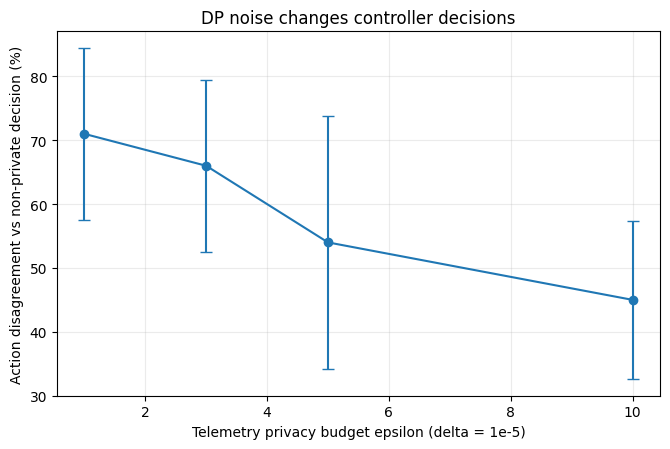

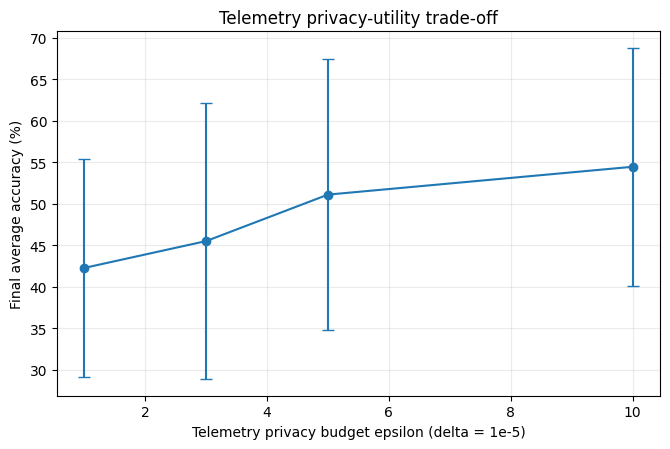

In [11]:
# Cell 11 | ---------- Epsilon sweep and action-disagreement analysis ----------
# ---------- Epsilon sweep and action-disagreement analysis ----------

EPSILONS = [1.0, 3.0, 5.0, 10.0]
eps_rows = []

for seed in EPS_SWEEP_SEEDS:
    for eps in EPSILONS:
        if eps == CFG["epsilon_main"]:
            # Reuse the already-computed main run at epsilon=10.
            row = main_results[
                (main_results["method"] == "PA-AgentFCL")
                & (main_results["seed"] == seed)
            ].iloc[0].to_dict()
        else:
            checkpoint=OUTPUT_DIR/f"epsilon_{eps:g}_seed{seed}_drift{DRIFT_MODE}.json"
            if checkpoint.exists():
                row=json.loads(checkpoint.read_text())
            else:
                row, eps_hist = run_one(
                    "PA-AgentFCL", seed, domains, epsilon=eps, verbose=False)
                checkpoint.write_text(json.dumps(row, indent=2, default=float))
                (OUTPUT_DIR/f"epsilon_{eps:g}_seed{seed}_history.json").write_text(
                    json.dumps(eps_hist, indent=2, default=float))

        row["epsilon_target"] = eps
        eps_rows.append(row)

epsilon_df = pd.DataFrame(eps_rows)
epsilon_df.to_csv(
    OUTPUT_DIR / "epsilon_sweep_results.csv", index=False
)

epsilon_summary = (
    epsilon_df.groupby("epsilon_target", as_index=False)
    .agg(
        disagreement_mean=("action_disagreement_rate", "mean"),
        disagreement_std=("action_disagreement_rate", "std"),
        final_acc_mean=("final_avg_accuracy", "mean"),
        final_acc_std=("final_avg_accuracy", "std"),
        forgetting_mean=("mean_forgetting", "mean"),
        forgetting_std=("mean_forgetting", "std"),
    )
)

display(epsilon_summary.round(4))

# Plot 1: epsilon vs DP-induced action disagreement.
fig, ax = plt.subplots(figsize=(6.8, 4.6))
x = epsilon_summary["epsilon_target"].to_numpy()
y = 100 * epsilon_summary["disagreement_mean"].to_numpy()
sd = 100 * epsilon_summary["disagreement_std"].fillna(0).to_numpy()
n = max(len(EPS_SWEEP_SEEDS), 1)
ci = stats.t.ppf(0.975, n - 1) * sd / math.sqrt(n) if n > 1 else np.zeros_like(sd)

ax.errorbar(x, y, yerr=ci, marker="o", capsize=4)
ax.set_xlabel("Telemetry privacy budget epsilon (delta = 1e-5)")
ax.set_ylabel("Action disagreement vs non-private decision (%)")
ax.set_title("DP noise changes controller decisions")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "epsilon_vs_action_disagreement.png",
    dpi=220,
    bbox_inches="tight",
)
plt.show()

# Plot 2: privacy-utility curve.
fig, ax = plt.subplots(figsize=(6.8, 4.6))
yacc = 100 * epsilon_summary["final_acc_mean"].to_numpy()
sdacc = 100 * epsilon_summary["final_acc_std"].fillna(0).to_numpy()
ciacc = stats.t.ppf(0.975, n - 1) * sdacc / math.sqrt(n) if n > 1 else np.zeros_like(sdacc)

ax.errorbar(x, yacc, yerr=ciacc, marker="o", capsize=4)
ax.set_xlabel("Telemetry privacy budget epsilon (delta = 1e-5)")
ax.set_ylabel("Final average accuracy (%)")
ax.set_title("Telemetry privacy-utility trade-off")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "epsilon_vs_accuracy.png",
    dpi=220,
    bbox_inches="tight",
)
plt.show()

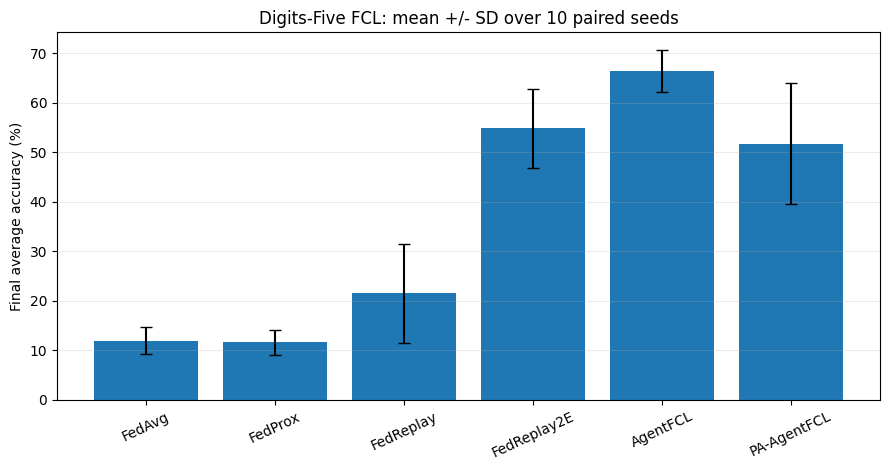

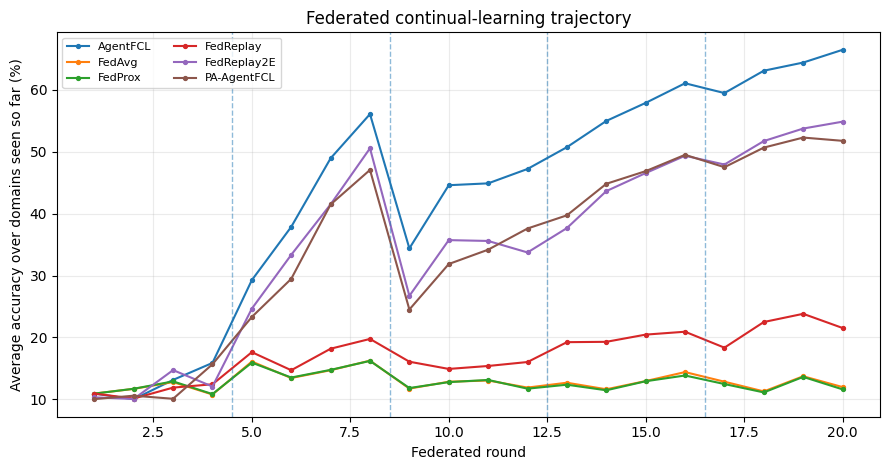

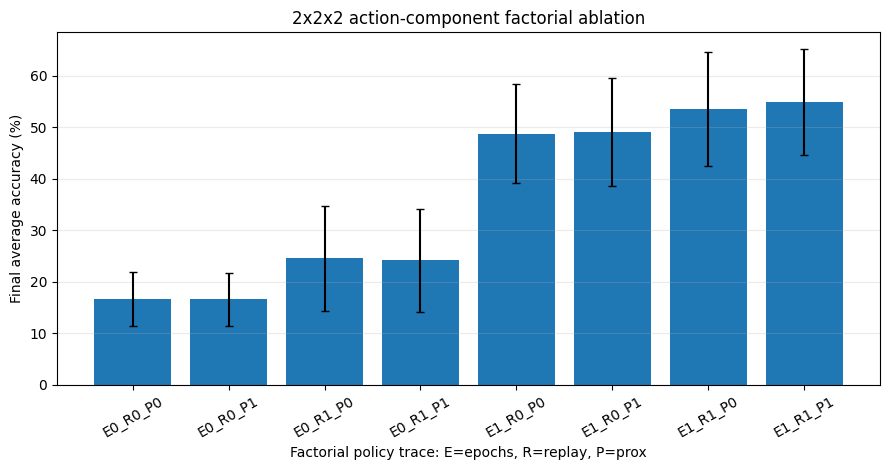

In [12]:
# Cell 12 | ---------- Paper-ready figures ----------
# ---------- Paper-ready figures ----------

# Final accuracy.
plot_df = main_summary.copy()
fig, ax = plt.subplots(figsize=(9.0, 4.8))
ax.bar(
    plot_df["method"],
    100 * plot_df["final_avg_accuracy_mean"],
    yerr=100 * plot_df["final_avg_accuracy_std"],
    capsize=4,
)
ax.set_ylabel("Final average accuracy (%)")
ax.set_title(
    f"Digits-Five FCL: mean +/- SD over {len(MAIN_SEEDS)} paired seeds"
)
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "main_final_accuracy.png",
    dpi=220,
    bbox_inches="tight",
)
plt.show()

# Continual-learning trajectory.
traj = (
    main_history.groupby(
        ["method", "round"], as_index=False
    )["avg_seen_accuracy"].mean()
)

fig, ax = plt.subplots(figsize=(9.0, 4.8))
for method, g in traj.groupby("method", sort=False):
    ax.plot(
        g["round"],
        100 * g["avg_seen_accuracy"],
        marker="o",
        markersize=2.8,
        label=method,
    )

for boundary in range(1, len(domains)):
    ax.axvline(
        boundary * CFG["rounds_per_domain"] + 0.5,
        linestyle="--",
        linewidth=1,
        alpha=0.5,
    )

ax.set_xlabel("Federated round")
ax.set_ylabel("Average accuracy over domains seen so far (%)")
ax.set_title("Federated continual-learning trajectory")
ax.legend(ncol=2, fontsize=8)
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "main_continual_trajectory.png",
    dpi=220,
    bbox_inches="tight",
)
plt.show()

# Factorial conditions.
fs = factorial_summary.sort_values(["E", "R", "P"])

fig, ax = plt.subplots(figsize=(9.0, 4.8))
ax.bar(
    fs["variant"],
    100 * fs["final_acc_mean"],
    yerr=100 * fs["final_acc_std"].fillna(0),
    capsize=3,
)
ax.set_ylabel("Final average accuracy (%)")
ax.set_xlabel("Factorial policy trace: E=epochs, R=replay, P=prox")
ax.set_title("2x2x2 action-component factorial ablation")
ax.tick_params(axis="x", rotation=30)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "factorial_2x2x2_accuracy.png",
    dpi=220,
    bbox_inches="tight",
)
plt.show()

In [13]:
# Cell 13 | ---------- Sanity checks and publication guardrails ----------
# ---------- Sanity checks and publication guardrails ----------

# 1) Main experiment uses the real five-domain benchmark.
assert [d["name"] for d in domains] == DOMAIN_ORDER
assert len(domains) == 5

# 2) CNN is substantially larger/stronger than the original tiny MLP.
assert model_parameter_count() > 100_000

# 3) LR is globally fixed; it is no longer bundled with the action.
assert isinstance(CFG["lr"], float)
for name in ACTION_TARGETS:
    a = materialize_action(name)
    assert math.isclose(a["lr"], CFG["lr"])

# 4) All eight factorial combinations are present.
assert len(factorial_summary) == 8
assert set(factorial_summary["variant"]) == {
    f"E{int(E)}_R{int(R)}_P{int(P)}"
    for E, R, P in FACTORIAL_MASKS
}

# 5) Epsilon sweep is complete.
assert set(epsilon_df["epsilon_target"].unique()) == {
    1.0, 3.0, 5.0, 10.0
}

# 6) Telemetry accountant reaches each requested epsilon.
for _, row in epsilon_df.iterrows():
    assert math.isclose(
        float(row["epsilon_telemetry"]),
        float(row["epsilon_target"]),
        rel_tol=1e-9,
        abs_tol=1e-9,
    )

# 7) Partial participation and dropout are actually active.
assert (
    main_results["avg_active_clients"] < CFG["n_clients"]
).all()
assert (
    main_results["realized_dropout_given_selected"] > 0
).all()

# 8) Headline paper mode has 10 paired seeds.
if RUN_MODE == "paper":
    assert len(MAIN_SEEDS) == 10
    assert int(paired_stats.loc[0, "n_paired_seeds"]) == 10

# 9) Core results are finite.
numeric = main_results[
    [
        "final_avg_accuracy",
        "mean_forgetting",
        "avg_local_epochs_per_round",
        "avg_active_clients",
    ]
].to_numpy()
assert np.isfinite(numeric).all()

print("PASS: Digits-Five benchmark loaded.")
print("PASS: CNN model used.")
print("PASS: paired headline statistics configured.")
print("PASS: full 2x2x2 action-component factorial ablation completed.")
print("PASS: epsilon sweep {1,3,5,10} completed.")
print("PASS: partial participation and client dropout are active.")
print("PASS: no end-to-end DP claim is made for the released model.")

# Non-cryptographic arithmetic check only.
def masked_aggregation_arithmetic_check(seed=123):
    rng = np.random.default_rng(seed)
    updates = [
        torch.tensor(rng.normal(size=20), dtype=torch.float32)
        for _ in range(4)
    ]
    weights = [3.0, 2.0, 4.0, 1.0]
    total = sum(weights)
    masked = [
        updates[i] * weights[i]
        for i in range(len(updates))
    ]

    for i in range(len(updates)):
        for j in range(i + 1, len(updates)):
            m = torch.tensor(
                rng.normal(scale=0.01, size=20),
                dtype=torch.float32,
            )
            masked[i] = masked[i] + m
            masked[j] = masked[j] - m

    masked_mean = sum(masked) / total
    plain_mean = (
        sum(u * w for u, w in zip(updates, weights)) / total
    )
    return float(
        (masked_mean - plain_mean).abs().max()
    )

mask_err = masked_aggregation_arithmetic_check()
assert mask_err < 1e-6
print(
    f"PASS: pairwise-mask arithmetic cancels "
    f"(max error={mask_err:.2e})."
)
print(
    "CAUTION: this is NOT a production "
    "secure-aggregation implementation."
)

PASS: Digits-Five benchmark loaded.
PASS: CNN model used.
PASS: paired headline statistics configured.
PASS: full 2x2x2 action-component factorial ablation completed.
PASS: epsilon sweep {1,3,5,10} completed.
PASS: partial participation and client dropout are active.
PASS: no end-to-end DP claim is made for the released model.
PASS: pairwise-mask arithmetic cancels (max error=1.19e-07).
CAUTION: this is NOT a production secure-aggregation implementation.


## Reviewer extension and interpretation guardrails

**Scientific boundary.** The Gaussian release below has a conditional per-round sensitivity bound `2C/K` under **fixed-sized replacement adjacency**, given a fixed model trajectory and data-independent participation schedule. Since individual training updates are not privatized, prior client data can influence future global models and all later telemetry. Consequently **the notebook does not establish client-level DP for the full adaptive transcript**, controller actions, model trajectory, or final model. The epsilon values label the **nominal conditional Gaussian mechanism calibration** only. This cannot be repaired by merely increasing Gaussian noise; it requires a new mechanism/proof with protected model updates or rigorous adaptive accounting.

**Comparability.** `DRIFT_MODE="same_model"` fixes representation confounding and therefore results are a **new variant** not directly equal to the submitted manuscript's legacy numbers. `DRIFT_MODE="legacy"` is available for exact older-protocol reruns. Compute-matching requires counting SGD steps and examples, not just epochs. Randomly shuffling second-epoch decisions is budget-aligned by number of rounds but may not exactly match example/SGD exposure when client counts and replay vary; compare the logged counters.

**Reviewer scope.** Diagnostics below are generated from measured histories. Large benchmark expansions remain optional due to their cost and are not acceptance prerequisites.


In [14]:
# Reviewer extension | Privacy calibration checks and exact explanatory table
from IPython.display import display
rows=[]
for eps in [1.,3.,5.,10.]:
    rho, rho_step, mult = zcdp_noise_multiplier(CFG['rounds_per_domain']*len(domains),eps,CFG['delta'])
    assert math.isclose(epsilon_from_rho(rho, CFG['delta']), eps, rel_tol=1e-9)
    for k in [2,7,10,50,100]:
        sensitivity=2*CFG['telemetry_clip']/k
        rows.append(dict(epsilon_nominal=eps, active_clients=k, sensitivity_replacement=sensitivity,
                         sigma_per_coordinate=mult*sensitivity, rho_total=rho, rho_per_release=rho_step,
                         scope=DP_SCOPE))
pd.DataFrame(rows).to_csv(OUTPUT_DIR/'conditional_dp_calibration.csv',index=False)
display(pd.DataFrame(rows).round(4))
print('CAUTION: these parameters do NOT certify DP for the full training or adaptive telemetry transcript.')


,epsilon_nominal,active_clients,sensitivity_replacement,sigma_per_coordinate,rho_total,rho_per_release,scope
0,1.0,2,1.0000,21.9159,0.0208,0.0010,conditional_fixed_model_path_only
1,1.0,7,0.2857,6.2617,0.0208,0.0010,conditional_fixed_model_path_only
2,1.0,10,0.2000,4.3832,0.0208,0.0010,conditional_fixed_model_path_only
3,1.0,50,0.0400,0.8766,0.0208,0.0010,conditional_fixed_model_path_only
4,1.0,100,0.0200,0.4383,0.0208,0.0010,conditional_fixed_model_path_only
5,3.0,2,1.0000,7.5923,0.1735,0.0087,conditional_fixed_model_path_only
6,3.0,7,0.2857,2.1692,0.1735,0.0087,conditional_fixed_model_path_only
7,3.0,10,0.2000,1.5185,0.1735,0.0087,conditional_fixed_model_path_only
8,3.0,50,0.0400,0.3037,0.1735,0.0087,conditional_fixed_model_path_only
9,3.0,100,0.0200,0.1518,0.1735,0.0087,conditional_fixed_model_path_only


CAUTION: these parameters do NOT certify DP for the full training or adaptive telemetry transcript.


In [15]:
# Reviewer extension | Per-domain transitions, action confusion, threshold margins,
# paired epsilon uncertainty, and full 2x2x2 interactions.
if RUN_REVIEWER_DIAGNOSTICS:
    h = main_history.copy()
    transitions = h[h['round'] % CFG['rounds_per_domain'] == 0].copy()
    transitions.to_csv(OUTPUT_DIR/'domain_transition_rounds.csv', index=False)
    confusion = pd.crosstab(h.loc[h.method=='PA-AgentFCL','reference_nonprivate_action'],
                            h.loc[h.method=='PA-AgentFCL','action'])
    confusion.to_csv(OUTPUT_DIR/'private_controller_action_confusion.csv')
    disagreement_by_domain = (h[h.method=='PA-AgentFCL']
        .groupby('domain',as_index=False)['action_disagreement'].agg(['mean','sum','count']).reset_index())
    disagreement_by_domain.to_csv(OUTPUT_DIR/'disagreement_by_domain.csv',index=False)
    q=h[h.method=='PA-AgentFCL'].copy()
    q['margin_bin']=pd.cut(q['boundary_margin_raw'],[-1e-10,.02,.05,.1,np.inf],
                              labels=['<=0.02','0.02-0.05','0.05-0.10','>0.10'])
    margins=q.groupby('margin_bin',observed=True)['action_disagreement'].agg(['mean','count']).reset_index()
    margins.to_csv(OUTPUT_DIR/'disagreement_vs_boundary_margin.csv',index=False)
    rows=[]
    for factors in [('E',),('R',),('P',),('E','R'),('E','P'),('R','P'),('E','R','P')]:
        differences=[]
        for seed,g in factorial_df.groupby('seed'):
            signs=np.prod([2*g[f].to_numpy()-1 for f in factors],axis=0)
            differences.append(float(np.mean(signs * g.final_avg_accuracy.to_numpy())*2))
        d=np.asarray(differences)
        n=len(d)
        se=d.std(ddof=1)/math.sqrt(n) if n>1 else float('nan')
        ci=stats.t.ppf(.975,n-1)*se if n>1 else float('nan')
        rows.append({'interaction_or_main':'*'.join(factors),'effect_pp':100*d.mean(),
                     'ci95_low_pp':100*(d.mean()-ci),'ci95_high_pp':100*(d.mean()+ci),
                     'n_seeds':n})
    effects=pd.DataFrame(rows)
    effects.to_csv(OUTPUT_DIR/'factorial_all_effects_including_interactions.csv',index=False)
    # Paired seed-level epsilon loss vs same-seed non-private baseline.
    eps_paired=epsilon_df.merge(main_results[main_results.method=='AgentFCL'][['seed','final_avg_accuracy']],
                               on='seed',suffixes=('_private','_nonprivate'),validate='many_to_one')
    eps_paired['accuracy_loss_pp']=100*(eps_paired.final_avg_accuracy_nonprivate-
                                      eps_paired.final_avg_accuracy_private)
    eps_paired.to_csv(OUTPUT_DIR/'epsilon_paired_accuracy_losses.csv',index=False)
    print('Action confusion:');display(confusion)
    print('Interaction estimates:');display(effects.round(3))
    print('Epsilon paired loss:');display(eps_paired.groupby('epsilon_target')['accuracy_loss_pp'].agg(['mean','std','count']).round(3))


Action confusion:


action,balanced,plastic,retention
reference_nonprivate_action,,,
balanced,3,1,6
retention,44,40,106


Interaction estimates:


,interaction_or_main,effect_pp,ci95_low_pp,ci95_high_pp,n_seeds
0,E,31.037,24.179,37.894,5
1,R,6.518,1.612,11.425,5
2,P,0.289,-0.172,0.749,5
3,E*R,-1.207,-5.181,2.767,5
4,E*P,0.489,0.120,0.859,5
5,R*P,0.161,-0.940,1.262,5
6,E*R*P,0.366,-0.244,0.976,5


Epsilon paired loss:


,mean,std,count
epsilon_target,,,
1.0,25.563,9.113,5
3.0,22.329,12.146,5
5.0,16.731,11.996,5
10.0,13.379,10.503,5


In [16]:
# Reviewer extension | Randomized-epoch control, fixed 2-epoch action-trace control
# Run for each ablation seed; checkpoint individually to survive Colab disconnects.
budget_rows=[]
if RUN_BUDGET_CONTROLS:
    for seed in ABLATION_SEEDS:
        ref=main_history[(main_history.method=='AgentFCL')&(main_history.seed==seed)].sort_values('round')
        trace=ref.action.tolist()
        epoch_trace=ref.epochs.astype(int).to_numpy()
        if not trace: raise RuntimeError(f'Missing AgentFCL trace for {seed}')
        rng=np.random.default_rng(4_000_000+seed)
        permuted=epoch_trace.copy();rng.shuffle(permuted)
        for label,extra in [('TraceFixed2',{'epoch_policy':'fixed_two'}),
                            ('TraceShuffledEpochs',{'forced_epoch_trace':permuted})]:
            cp=OUTPUT_DIR/f'budget_{label}_seed{seed}_drift{DRIFT_MODE}.json'
            if cp.exists():
                sm=json.loads(cp.read_text())
            else:
                print('Budget control:',label,'seed',seed,flush=True)
                sm,_=run_one('PolicyTrace',seed,domains,forced_actions=trace,
                             factor_mask=(True,True,True),verbose=True,**extra)
                sm['variant']=label
                cp.write_text(json.dumps(sm,indent=2,default=float))
            sm['variant']=label
            budget_rows.append(sm)
    budget_df=pd.DataFrame(budget_rows)
    budget_df.to_csv(OUTPUT_DIR/'reviewer_budget_controls.csv',index=False)
    display(budget_df.groupby('variant')[['final_avg_accuracy','sgd_steps',
         'training_example_exposures','client_epoch_executions']].agg(['mean','std']).round(3))
    print('Compare actual SGD steps and example exposures before saying compute-matched.')


Budget control: TraceFixed2 seed 0
PolicyTrace   seed= 0 acc=66.84 forget=0.29 epochs/rnd=2.00
Budget control: TraceShuffledEpochs seed 0
PolicyTrace   seed= 0 acc=63.75 forget=1.07 epochs/rnd=1.95
Budget control: TraceFixed2 seed 1
PolicyTrace   seed= 1 acc=56.66 forget=0.58 epochs/rnd=2.00
Budget control: TraceShuffledEpochs seed 1
PolicyTrace   seed= 1 acc=51.71 forget=0.39 epochs/rnd=1.90
Budget control: TraceFixed2 seed 2
PolicyTrace   seed= 2 acc=68.09 forget=0.83 epochs/rnd=2.00
Budget control: TraceShuffledEpochs seed 2
PolicyTrace   seed= 2 acc=66.74 forget=0.99 epochs/rnd=1.95
Budget control: TraceFixed2 seed 3
PolicyTrace   seed= 3 acc=67.97 forget=0.00 epochs/rnd=2.00
Budget control: TraceShuffledEpochs seed 3
PolicyTrace   seed= 3 acc=66.31 forget=0.00 epochs/rnd=1.95
Budget control: TraceFixed2 seed 4
PolicyTrace   seed= 4 acc=71.78 forget=0.00 epochs/rnd=2.00
Budget control: TraceShuffledEpochs seed 4
PolicyTrace   seed= 4 acc=70.48 forget=0.00 epochs/rnd=1.95


final_avg_accuracy        sgd_steps          \
                                  mean    std      mean     std   
variant                                                           
TraceFixed2                      0.663  0.057    1664.8  70.009   
TraceShuffledEpochs              0.638  0.072    1615.6  77.054   

                    training_example_exposures            \
                                          mean       std   
variant                                                    
TraceFixed2                            94902.0  3945.389   
TraceShuffledEpochs                    92100.0  4318.683   

                    client_epoch_executions         
                                       mean    std  
variant                                             
TraceFixed2                           250.8  8.556  
TraceShuffledEpochs                   243.6  9.607

Compare actual SGD steps and example exposures before saying compute-matched.


In [17]:
# Reviewer extension | Optional sensitivity to domain order and domain exposure.
# Large runs are OFF by default. Enable switches in configuration for Colab GPU.
extension_rows=[]
if RUN_DOMAIN_ORDER_SENSITIVITY:
    for order_name,indices in [('reverse',[4,3,2,1,0]),('swap_middle',[0,2,1,4,3])]:
        ordered=[domains[i] for i in indices]
        for seed in ABLATION_SEEDS:
            for method in ['AgentFCL','FedReplay2E']:
                sm,_=run_one(method,seed,ordered,verbose=True)
                sm.update(experiment='domain_order',variant=order_name)
                extension_rows.append(sm)
if RUN_LONGER_EXPOSURE:
    old_rpd=CFG['rounds_per_domain']
    try:
        CFG['rounds_per_domain']=8
        for seed in ABLATION_SEEDS:
            for method in ['AgentFCL','FedReplay2E']:
                sm,_=run_one(method,seed,domains,verbose=True)
                sm.update(experiment='longer_exposure',variant='8_rounds_per_domain')
                extension_rows.append(sm)
    finally:
        CFG['rounds_per_domain']=old_rpd
if extension_rows:
    pd.DataFrame(extension_rows).to_csv(OUTPUT_DIR/'additional_domain_experiments.csv',index=False)


In [22]:
# Reviewer extension | Optional larger-client feasibility study (50/100).
# Computationally expensive; partitions/sample caps are deliberately unchanged.
scale_rows=[]
if RUN_CLIENT_SCALE:
    old_clients, old_min=CFG['n_clients'],CFG['min_client_samples']
    try:
        CFG['min_client_samples']=min(10,old_min)
        for count in [50,100]:
            CFG['n_clients']=count
            for seed in ABLATION_SEEDS:
                for method in ['PA-AgentFCL','AgentFCL']:
                    sm,_=run_one(method,seed,domains,epsilon=CFG['epsilon_main'],verbose=True)
                    sm.update(experiment='client_scale',client_count=count)
                    scale_rows.append(sm)
    finally:
        CFG['n_clients'], CFG['min_client_samples']=old_clients,old_min
if scale_rows:
    pd.DataFrame(scale_rows).to_csv(OUTPUT_DIR/'client_scale_experiments.csv',index=False)


In [23]:
# Reviewer extension | Optional threshold sensitivity with predeclared perturbations.
# These configurations must not be selected based on test-stream performance.
threshold_rows=[]
if RUN_THRESHOLD_SENSITIVITY:
    thresholds=[('default',.15,.10,.05),('lower_thresholds',.10,.075,.025),
                ('higher_thresholds',.20,.15,.075)]
    for label,low,gap_r,gap_p in thresholds:
        for seed in ABLATION_SEEDS:
            for method in ['AgentFCL','PA-AgentFCL']:
                checkpoint=OUTPUT_DIR/f'threshold_{label}_{method}_seed{seed}.json'
                if checkpoint.exists():
                    sm=json.loads(checkpoint.read_text())
                else:
                    sm,_=run_one(method,seed,domains,epsilon=CFG['epsilon_main'],
                         threshold_policy={'low_cut':low,'retention_gap':gap_r,
                                           'plastic_gap':gap_p},verbose=True)
                    checkpoint.write_text(json.dumps(sm,indent=2,default=float))
                sm.update(threshold_variant=label)
                threshold_rows.append(sm)
if threshold_rows:
    pd.DataFrame(threshold_rows).to_csv(OUTPUT_DIR/'threshold_sensitivity.csv',index=False)


In [24]:

# Cell 22 | Complete remaining INMIC 2026 reviewer experiments
# Resume from existing notebook state; DO NOT rerun completed main experiments.

import os, json, time, shutil, zipfile, traceback
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

# 1. Verify that original notebook state is available
required = ["run_one", "domains", "CFG", "OUTPUT_DIR", "DEVICE"]
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(
        "Original Colab runtime state is missing: " + str(missing) +
        ". Reconnect to the original running session. Do not "
        "rerun the main experiments unnecessarily."
    )

assert len(domains) == 5, "Digits-Five dataset is not loaded."
assert CFG["n_clients"] == 10, "Expected original 10-client config."
assert CFG["rounds_per_domain"] == 4, "Expected 4 rounds/domain."

OUTPUT_DIR = Path(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 2. Set remaining experiment configurations
SEEDS = [0, 1, 2, 3, 4]

RUN_THRESHOLDS = True
RUN_DOMAIN_ORDERS = True
RUN_LONGER_EXPOSURE = True
RUN_SCALABILITY = True

# These are expensive experiments, especially at 100 clients.
# Change only these switches to False if resources are insufficient.

# 3. Enable persistent saving in Google Drive
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BACKUP_DIR = Path(
        "/content/drive/MyDrive/INMIC2026_PA_AgentFCL"
    )
except Exception as e:
    print("Drive unavailable:", e)
    BACKUP_DIR = OUTPUT_DIR / "persistent_backup"
    print("WARNING: backup is local to the runtime.")

BACKUP_DIR.mkdir(parents=True, exist_ok=True)
NEW_DIR = OUTPUT_DIR / "remaining_reviewer_experiments"
NEW_DIR.mkdir(parents=True, exist_ok=True)

print("Original results:", OUTPUT_DIR)
print("New results:", NEW_DIR)
print("Persistent backup:", BACKUP_DIR)

# 4. Resume-safe execution and checkpoint handling
all_rows = []
failures = []

def run_remaining(label, method, seed, domain_list=None,
                  epsilon=None, threshold_policy=None,
                  clients=None, rounds_per_domain=None):

    if domain_list is None:
        domain_list = domains

    checkpoint = NEW_DIR / f"{label}_{method}_seed{seed}.json"
    backup = BACKUP_DIR / checkpoint.name

    for candidate in [checkpoint, backup]:
        if candidate.exists():
            try:
                result = json.loads(candidate.read_text())
                if result.get("_completed", False):
                    print("SKIP completed:", checkpoint.name)
                    all_rows.append(result)
                    if not checkpoint.exists():
                        shutil.copy2(candidate, checkpoint)
                    return result
            except (ValueError, OSError):
                print("Invalid checkpoint; rerunning:", candidate)

    old_cfg = CFG.copy()
    started = time.time()

    try:
        if clients is not None:
            CFG["n_clients"] = int(clients)
            CFG["min_client_samples"] = (
                10 if clients > 10 else old_cfg["min_client_samples"]
            )

        if rounds_per_domain is not None:
            CFG["rounds_per_domain"] = int(rounds_per_domain)

        print(
            f"RUN {label} | {method} | seed={seed} | "
            f"clients={CFG['n_clients']} | "
            f"rounds/domain={CFG['rounds_per_domain']}",
            flush=True
        )

        summary, history = run_one(
            method=method,
            seed=seed,
            domains=domain_list,
            epsilon=epsilon,
            threshold_policy=threshold_policy,
            verbose=True
        )

        summary.update({
            "experiment": label,
            "variant": label,
            "n_clients_configured": CFG["n_clients"],
            "rounds_per_domain_configured":
                CFG["rounds_per_domain"],
            "runtime_seconds": time.time() - started,
            "_completed": True
        })

        # Save immediately, before starting the next experiment.
        tmp = checkpoint.with_suffix(".tmp")
        tmp.write_text(json.dumps(summary, indent=2, default=float))
        tmp.replace(checkpoint)

        history_path = NEW_DIR / (
            f"{label}_{method}_seed{seed}_history.json"
        )
        history_path.write_text(
            json.dumps(history, default=float)
        )

        shutil.copy2(checkpoint, backup)
        shutil.copy2(history_path, BACKUP_DIR / history_path.name)

        all_rows.append(summary)
        return summary

    except Exception as exc:
        failures.append({
            "experiment": label,
            "method": method,
            "seed": seed,
            "error": repr(exc)
        })
        print("FAILED:", label, method, seed, repr(exc))
        traceback.print_exc()
        return None

    finally:
        CFG.clear()
        CFG.update(old_cfg)

# 5. Reviewer 2.4 — Predeclared threshold sensitivity
thresholds = [
    ("threshold_default", 0.15, 0.10, 0.05),
    ("threshold_lower", 0.10, 0.075, 0.025),
    ("threshold_higher", 0.20, 0.15, 0.075)
]

if RUN_THRESHOLDS:
    print("\n=== REVIEWER 2.4: THRESHOLDS ===")
    for name, low, rgap, pgap in thresholds:
        policy = {
            "low_cut": low,
            "retention_gap": rgap,
            "plastic_gap": pgap
        }
        for seed in SEEDS:
            for method in ["AgentFCL", "PA-AgentFCL"]:
                run_remaining(
                    name, method, seed,
                    epsilon=10.0 if method == "PA-AgentFCL"
                    else None,
                    threshold_policy=policy
                )

# 6. Reviewer 2.5 — Alternative domain orders
orders = {
    "reverse_order": [4, 3, 2, 1, 0],
    "swap_middle_order": [0, 2, 1, 4, 3]
}

if RUN_DOMAIN_ORDERS:
    print("\n=== REVIEWER 2.5: DOMAIN ORDERS ===")
    for name, order in orders.items():
        reordered = [domains[i] for i in order]
        for seed in SEEDS:
            for method in ["AgentFCL", "FedReplay2E"]:
                run_remaining(
                    name, method, seed,
                    domain_list=reordered
                )

# 7. Reviewer 2.5 — Longer adaptation period
if RUN_LONGER_EXPOSURE:
    print("\n=== REVIEWER 2.5: LONGER EXPOSURE ===")
    for seed in SEEDS:
        for method in ["AgentFCL", "FedReplay2E"]:
            run_remaining(
                "eight_rounds_per_domain",
                method,
                seed,
                rounds_per_domain=8
            )

# 8. Reviewer 3 — 50 and 100 clients
if RUN_SCALABILITY:
    print("\n=== REVIEWER 3: SCALABILITY ===")
    for count in [50, 100]:
        for seed in SEEDS:
            for method in ["AgentFCL", "PA-AgentFCL"]:
                run_remaining(
                    f"scale_{count}_clients",
                    method,
                    seed,
                    clients=count,
                    epsilon=10.0 if method == "PA-AgentFCL"
                    else None
                )

# 9. Reload all valid completed checkpoints
# Includes completed runs from previous attempts.
collected = []
for path in sorted(NEW_DIR.glob("*.json")):
    if path.name.endswith("_history.json"):
        continue
    try:
        row = json.loads(path.read_text())
        if isinstance(row, dict) and row.get("_completed", False):
            collected.append(row)
    except (OSError, ValueError):
        pass

results = pd.DataFrame(collected)

if not results.empty:
    results.to_csv(
        NEW_DIR / "remaining_reviewer_results.csv",
        index=False
    )

    summary_table = results.groupby(
        ["experiment", "method"], dropna=False
    ).agg(
        n_seeds=("seed", "nunique"),
        accuracy_mean=("final_avg_accuracy", "mean"),
        accuracy_std=("final_avg_accuracy", "std"),
        forgetting_mean=("mean_forgetting", "mean"),
        sgd_steps_mean=("sgd_steps", "mean"),
        example_exposures_mean=(
            "training_example_exposures", "mean"
        )
    ).reset_index()

    summary_table.to_csv(
        NEW_DIR / "remaining_reviewer_summary.csv",
        index=False
    )

    print("\n=== REVIEWER EXPERIMENT SUMMARY ===")
    display(summary_table)

# 10. Save failures and experiment manifest
pd.DataFrame(failures).to_csv(
    NEW_DIR / "execution_failures.csv", index=False
)

manifest = {
    "paper": "INMIC2026_Paper205",
    "original_notebook_preserved": True,
    "original_results_folder": str(OUTPUT_DIR),
    "continuation_experiments": [
        "threshold_sensitivity",
        "alternative_domain_order",
        "longer_exposure",
        "50_100_client_scalability"
    ],
    "completed_run_count": len(results),
    "failed_run_count": len(failures),
    "dp_scope": "conditional_fixed_model_path_only",
    "full_adaptive_transcript_dp_proven": False,
    "non_digit_benchmark_completed": False
}

(NEW_DIR / "reviewer_manifest.json").write_text(
    json.dumps(manifest, indent=2)
)

# 11. Combine old results with all new results
archive = OUTPUT_DIR.parent / (
    "pa_agentfcl_complete_reviewer_results.zip"
)

with zipfile.ZipFile(
    archive, "w", compression=zipfile.ZIP_DEFLATED
) as z:
    for item in OUTPUT_DIR.rglob("*"):
        if item.is_file() and item.resolve() != archive.resolve():
            z.write(
                item,
                arcname=str(item.relative_to(OUTPUT_DIR.parent))
            )

shutil.copy2(archive, BACKUP_DIR / archive.name)

print("\n=== FINAL STATUS ===")
print("Completed new runs:", len(results))
print("Failures this execution:", len(failures))
print("Original results preserved:", OUTPUT_DIR)
print("Combined results ZIP:", archive)
print("Drive backup:", BACKUP_DIR / archive.name)

if failures:
    print(
        "Some runs failed. Fix the reported error and rerun "
        "THIS CELL only; completed checkpoints will be skipped."
    )
else:
    print("All selected extension runs completed successfully.")

print(
    "Privacy note: full adaptive telemetry DP remains unproven."
)


Mounted at /content/drive
Original results: /content/pa_agentfcl_outputs
New results: /content/pa_agentfcl_outputs/remaining_reviewer_experiments
Persistent backup: /content/drive/MyDrive/INMIC2026_PA_AgentFCL

=== REVIEWER 2.4: THRESHOLDS ===
RUN threshold_default | AgentFCL | seed=0 | clients=10 | rounds/domain=4
AgentFCL      seed= 0 acc=65.71 forget=0.24 epochs/rnd=1.95
RUN threshold_default | PA-AgentFCL | seed=0 | clients=10 | rounds/domain=4
PA-AgentFCL   seed= 0 acc=45.66 forget=8.02 epochs/rnd=1.70
RUN threshold_default | AgentFCL | seed=1 | clients=10 | rounds/domain=4
AgentFCL      seed= 1 acc=63.76 forget=0.55 epochs/rnd=1.90
RUN threshold_default | PA-AgentFCL | seed=1 | clients=10 | rounds/domain=4
PA-AgentFCL   seed= 1 acc=59.85 forget=0.56 epochs/rnd=1.95
RUN threshold_default | AgentFCL | seed=2 | clients=10 | rounds/domain=4
AgentFCL      seed= 2 acc=67.54 forget=0.75 epochs/rnd=1.95
RUN threshold_default | PA-AgentFCL | seed=2 | clients=10 | rounds/domain=4
PA-AgentF

,experiment,method,n_seeds,accuracy_mean,accuracy_std,forgetting_mean,sgd_steps_mean,example_exposures_mean
0,eight_rounds_per_domain,AgentFCL,5,0.780411,0.021430,0.019491,3222.2,183348.8
1,eight_rounds_per_domain,FedReplay2E,5,0.752325,0.024202,0.027261,2952.0,170739.2
2,reverse_order,AgentFCL,5,0.458685,0.066131,0.002452,1644.0,93688.8
3,reverse_order,FedReplay2E,5,0.377676,0.036541,0.003911,1444.4,83736.4
4,scale_100_clients,AgentFCL,5,0.378473,0.059871,0.032228,5455.6,274669.4
5,scale_100_clients,PA-AgentFCL,5,0.379829,0.059228,0.031872,5455.6,274669.4
6,scale_50_clients,AgentFCL,5,0.631386,0.030413,0.009400,4721.4,262192.6
7,scale_50_clients,PA-AgentFCL,5,0.625281,0.024247,0.009550,4639.6,257314.8
8,swap_middle_order,AgentFCL,5,0.624285,0.057779,0.006200,1635.2,93144.0
9,swap_middle_order,FedReplay2E,5,0.530843,0.087439,0.009311,1438.4,83278.8



=== FINAL STATUS ===
Completed new runs: 80
Failures this execution: 0
Original results preserved: /content/pa_agentfcl_outputs
Combined results ZIP: /content/pa_agentfcl_complete_reviewer_results.zip
Drive backup: /content/drive/MyDrive/INMIC2026_PA_AgentFCL/pa_agentfcl_complete_reviewer_results.zip
All selected extension runs completed successfully.
Privacy note: full adaptive telemetry DP remains unproven.
